In [ ]:

import pandas as pd

df = pd.read_csv("/content/web-page-phishing.csv")

df.head()



,url_length,n_dots,n_hypens,n_underline,n_slash,n_questionmark,n_equal,n_at,n_and,n_exclamation,n_space,n_tilde,n_comma,n_plus,n_asterisk,n_hastag,n_dollar,n_percent,n_redirection,phishing
0,37,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,77,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1
2,126,4,1,2,0,1,3,0,2,0,0,0,0,0,0,0,0,0,1,1
3,18,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4,55,2,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0


In [ ]:

# Check the dataset size
print("Dataset Shape:", df.shape)

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check for duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())


Dataset Shape: (100077, 20)

Missing Values:
url_length        0
n_dots            0
n_hypens          0
n_underline       0
n_slash           0
n_questionmark    0
n_equal           0
n_at              0
n_and             0
n_exclamation     0
n_space           0
n_tilde           0
n_comma           0
n_plus            0
n_asterisk        0
n_hastag          0
n_dollar          0
n_percent         0
n_redirection     0
phishing          0
dtype: int64

Duplicate Records: 78186

Column Names:
['url_length', 'n_dots', 'n_hypens', 'n_underline', 'n_slash', 'n_questionmark', 'n_equal', 'n_at', 'n_and', 'n_exclamation', 'n_space', 'n_tilde', 'n_comma', 'n_plus', 'n_asterisk', 'n_hastag', 'n_dollar', 'n_percent', 'n_redirection', 'phishing']


Website Classification:
phishing
0    63715
1    36362
Name: count, dtype: int64


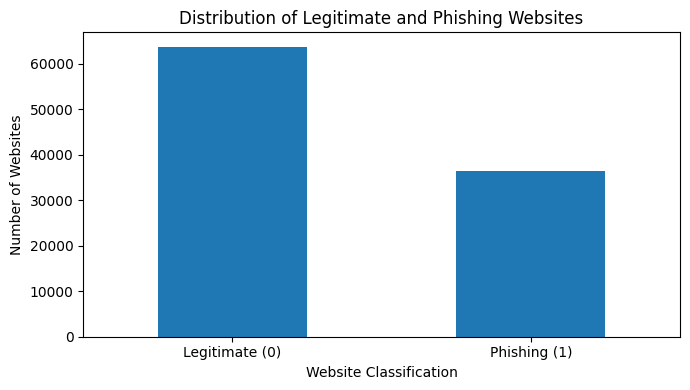

In [ ]:

import matplotlib.pyplot as plt

# Count legitimate and phishing websites
counts = df["phishing"].value_counts().sort_index()

print("Website Classification:")
print(counts)

# Create a bar chart
plt.figure(figsize=(7, 4))
counts.plot(kind="bar")

plt.title("Distribution of Legitimate and Phishing Websites")
plt.xlabel("Website Classification")
plt.ylabel("Number of Websites")
plt.xticks([0, 1], ["Legitimate (0)", "Phishing (1)"], rotation=0)

plt.tight_layout()
plt.show()


Average URL Length:
phishing
0    23.589971
1    66.491117
Name: url_length, dtype: float64


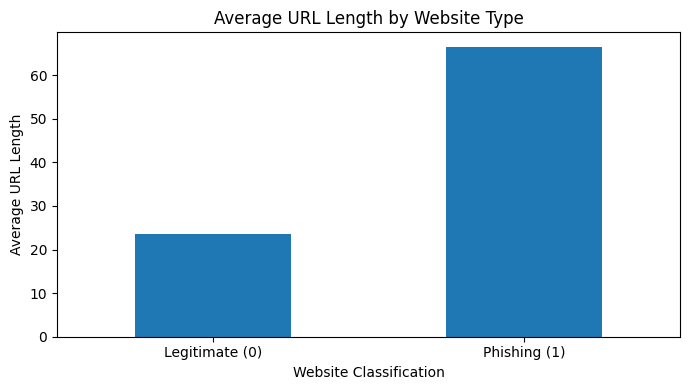

In [ ]:

import matplotlib.pyplot as plt

# Compare average URL lengths
average_length = df.groupby("phishing")["url_length"].mean()

print("Average URL Length:")
print(average_length)

# Create graph
plt.figure(figsize=(7, 4))
average_length.plot(kind="bar")

plt.title("Average URL Length by Website Type")
plt.xlabel("Website Classification")
plt.ylabel("Average URL Length")
plt.xticks([0, 1], ["Legitimate (0)", "Phishing (1)"], rotation=0)

plt.tight_layout()
plt.show()


Feature Correlations with Phishing:
n_slash           0.611472
url_length        0.430125
n_equal           0.260462
n_and             0.189173
n_dots            0.181884
n_underline       0.168305
n_questionmark    0.167045
n_hypens          0.150413
n_at              0.109056
n_redirection    -0.050822
n_tilde           0.049616
n_exclamation     0.029358
n_comma           0.026512
n_percent         0.026117
n_dollar          0.025799
n_asterisk        0.019092
n_space           0.014757
n_hastag          0.010257
n_plus            0.006619
Name: phishing, dtype: float64


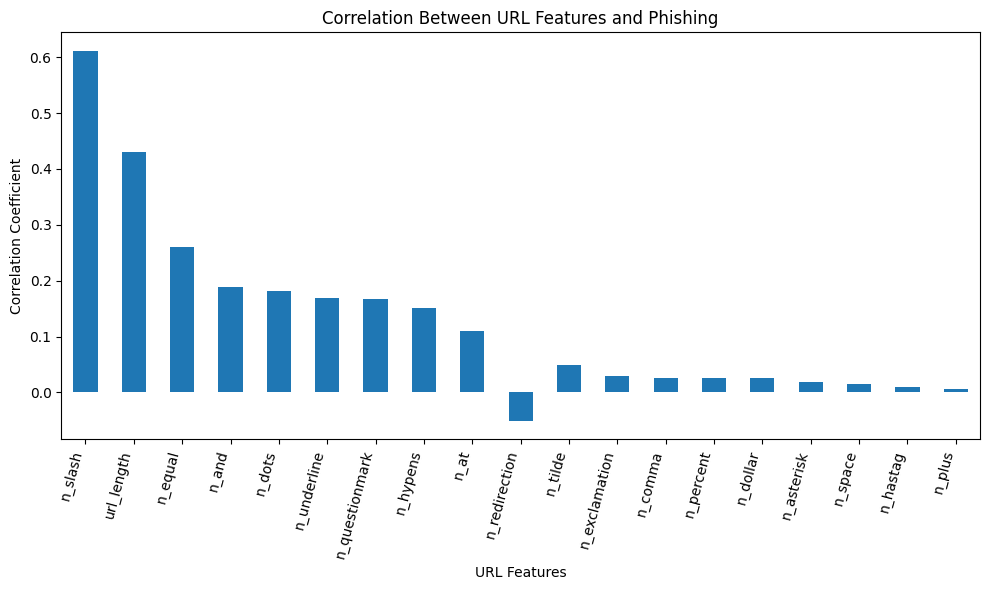

In [ ]:

import matplotlib.pyplot as plt

# Calculate correlations between features and phishing
correlations = df.corr(numeric_only=True)["phishing"].drop("phishing")

# Sort by strongest absolute correlation
correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

print("Feature Correlations with Phishing:")
print(correlations)

# Display correlation graph
plt.figure(figsize=(10, 6))
correlations.plot(kind="bar")

plt.title("Correlation Between URL Features and Phishing")
plt.xlabel("URL Features")
plt.ylabel("Correlation Coefficient")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


Average Number of Slashes:
phishing
0    0.290732
1    2.615423
Name: n_slash, dtype: float64


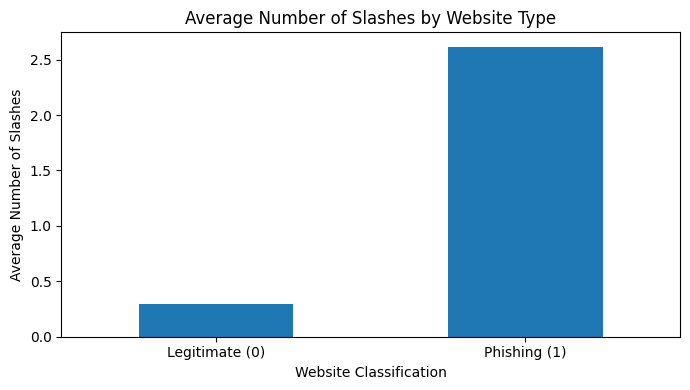

In [ ]:

import matplotlib.pyplot as plt

# Calculate average number of slashes
average_slashes = df.groupby("phishing")["n_slash"].mean()

print("Average Number of Slashes:")
print(average_slashes)

# Create comparison graph
plt.figure(figsize=(7, 4))
average_slashes.plot(kind="bar")

plt.title("Average Number of Slashes by Website Type")
plt.xlabel("Website Classification")
plt.ylabel("Average Number of Slashes")
plt.xticks([0, 1], ["Legitimate (0)", "Phishing (1)"], rotation=0)

plt.tight_layout()
plt.show()


In [ ]:

# Step 4: Data Preprocessing

# Check duplicate records
print("Original dataset:", df.shape)

# Count duplicate rows
print("Duplicate records:", df.duplicated().sum())

# Check whether identical features have conflicting labels
features = df.drop(columns=["phishing"])

conflicts = df.groupby(
    list(features.columns)
)["phishing"].nunique()

print("Feature combinations with conflicting labels:",
      (conflicts > 1).sum())


Original dataset: (100077, 20)
Duplicate records: 78186
Feature combinations with conflicting labels: 1913


In [ ]:

# Step 4.1: Remove exact duplicate records

# Keep the original dataset unchanged
df_clean = df.drop_duplicates().copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

# Check class distribution after cleaning
print("\nClass Distribution After Cleaning:")
print(df_clean["phishing"].value_counts())


Original dataset: (100077, 20)
Cleaned dataset: (21891, 20)
Remaining duplicates: 0

Class Distribution After Cleaning:
phishing
1    15872
0     6019
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

# Separate features and target variable
X = df_clean.drop(columns=["phishing"])
y = df_clean["phishing"]

# Group rows with identical feature values
groups = pd.util.hash_pandas_object(
    X, index=False
)

# Split data: approximately 80% train, 20% test
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True))

print("\nShared feature groups:",
      len(set(groups.iloc[train_idx]) &
          set(groups.iloc[test_idx])))


Training records: 17523
Testing records: 4368

Training class distribution:
phishing
1    0.721737
0    0.278263
Name: proportion, dtype: float64

Testing class distribution:
phishing
1    0.738324
0    0.261676
Name: proportion, dtype: float64

Shared feature groups: 0


In [ ]:

# Step 5: Machine Learning Models

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Model 1: Decision Tree
decision_tree = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

decision_tree.fit(X_train, y_train)

# Model 2: Random Forest
random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

# Make predictions
dt_predictions = decision_tree.predict(X_test)
rf_predictions = random_forest.predict(X_test)

# Compare accuracy
print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_predictions))

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))


Decision Tree Accuracy: 0.8141025641025641
Random Forest Accuracy: 0.8257783882783882


DECISION TREE RESULTS
              precision    recall  f1-score   support

           0       0.66      0.60      0.63      1143
           1       0.86      0.89      0.88      3225

    accuracy                           0.81      4368
   macro avg       0.76      0.74      0.75      4368
weighted avg       0.81      0.81      0.81      4368

RANDOM FOREST RESULTS
              precision    recall  f1-score   support

           0       0.75      0.50      0.60      1143
           1       0.84      0.94      0.89      3225

    accuracy                           0.83      4368
   macro avg       0.80      0.72      0.74      4368
weighted avg       0.82      0.83      0.81      4368



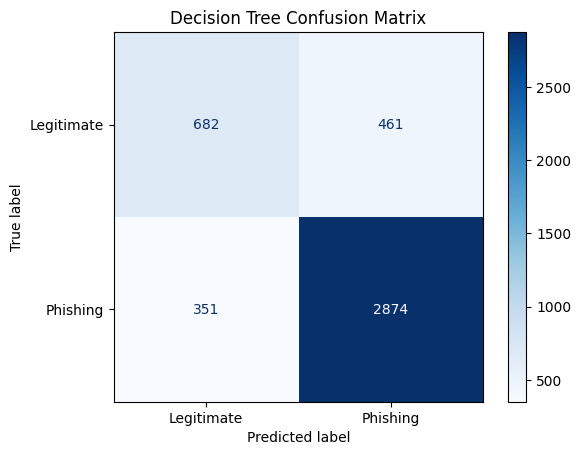

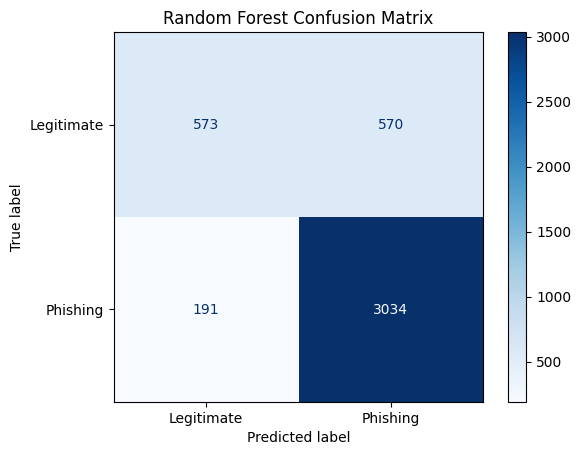

In [ ]:

# Step 6: Model Evaluation

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Decision Tree Evaluation
print("DECISION TREE RESULTS")
print(classification_report(y_test, dt_predictions))

# Random Forest Evaluation
print("RANDOM FOREST RESULTS")
print(classification_report(y_test, rf_predictions))

# Decision Tree Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_predictions,
    display_labels=["Legitimate", "Phishing"],
    cmap="Blues"
)
plt.title("Decision Tree Confusion Matrix")
plt.show()

# Random Forest Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["Legitimate", "Phishing"],
    cmap="Blues"
)
plt.title("Random Forest Confusion Matrix")
plt.show()



Random Forest Feature Importance:
n_slash           0.305447
url_length        0.194067
n_hypens          0.135803
n_equal           0.090770
n_dots            0.073022
n_redirection     0.046566
n_underline       0.034610
n_and             0.031203
n_at              0.028720
n_questionmark    0.020320
n_percent         0.018907
n_plus            0.007483
n_space           0.004044
n_tilde           0.003043
n_exclamation     0.002912
n_comma           0.001631
n_asterisk        0.001127
n_dollar          0.000304
n_hastag          0.000020
dtype: float64


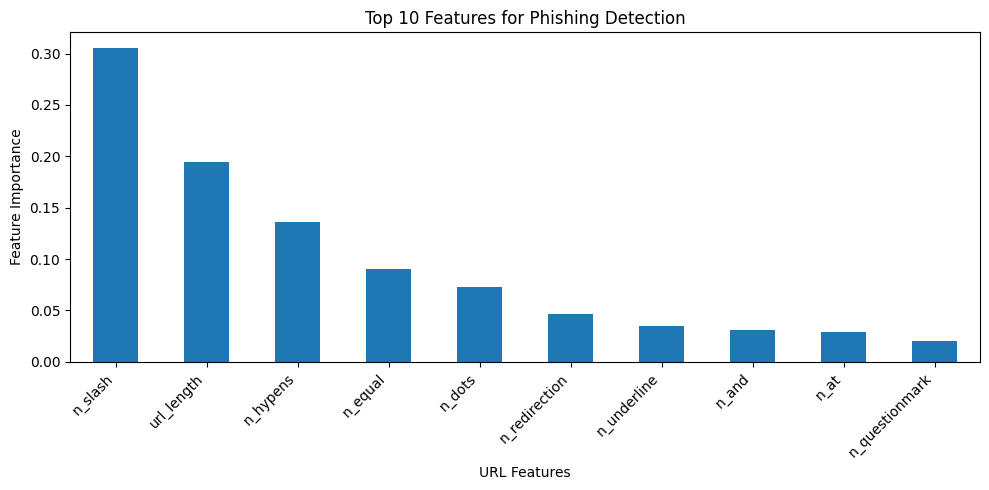

In [ ]:

# Step 7.1: Random Forest Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance scores
importance = pd.Series(
    random_forest.feature_importances_,
    index=X_train.columns
)

# Sort features by importance
importance = importance.sort_values(ascending=False)

print("Random Forest Feature Importance:")
print(importance)

# Display top 10 important features
plt.figure(figsize=(10, 5))
importance.head(10).plot(kind="bar")

plt.title("Top 10 Features for Phishing Detection")
plt.xlabel("URL Features")
plt.ylabel("Feature Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
